# TC3-47 — Analisar diferenças por município, UF, rede e série

**Objetivo:** avaliar como a base e os resultados se comportam nos recortes geográficos e educacionais disponíveis, identificando diferenças entre municípios, unidades federativas (UF), redes de ensino e séries.

## Relação com os notebooks anteriores

- **TC3-43:** fornece o contexto da distribuição do target `alfabetizado` (aproximadamente 51,31% na classe 1 e 48,69% na classe 0, conforme análise anterior).
- **TC3-44 e TC3-45:** reforçam a necessidade de considerar distribuição, valores ausentes, duplicidades e possíveis valores extremos.
- **TC3-46:** identificou associação elevada entre `proficiencia` e `alfabetizado` (correlação aproximada de 0,796), além de associações moderadas com `presenca` e `preenchimento_caderno` (aproximadamente 0,402 cada). Este notebook aprofunda a exploração por grupos, sem tratar associação como causalidade.

## Escopo

1. Ler a base consolidada particionada por UF.
2. Identificar as colunas geográficas e educacionais realmente disponíveis.
3. Comparar quantidade de registros e proporção de `alfabetizado` por UF, rede e série.
4. Investigar diferenças entre municípios, incluindo tamanho da amostra e indicadores médios.
5. Explorar recortes combinados quando as colunas existirem.
6. Registrar achados, limitações e pontos que precisam de validação.

## Cuidados metodológicos

- A base contém milhões de linhas; as comparações devem ser agregadas antes de exibir ou plotar.
- Médias de municípios com poucos registros são instáveis. A tabela de municípios inclui um limite mínimo de observações ajustável.
- Diferenças descritivas não demonstram causalidade e não devem ser interpretadas automaticamente como desempenho atribuível à rede, UF ou município.
- `alfabetizado` é o target recebido pronto na base; este notebook não recalcula sua classificação.
- A associação entre `proficiencia` e `alfabetizado` observada no TC3-46 merece atenção antes da modelagem, mas não comprova, por si só, *data leakage*.


## 1. Preparação do ambiente

O notebook utiliza Polars para consultar os arquivos Parquet de forma eficiente e Polars/matplotlib/seaborn para tabelas e gráficos.


## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=normal; threads=4; RAM usada=29.9%; livre=10.8 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
from pathlib import Path
import warnings

import polars as pl
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

print("Polars:", pl.__version__)


Polars: 2.0.0


## 2. Localização e leitura dos arquivos

A estrutura esperada é `dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=SP/*.parquet`. O código procura a raiz do projeto a partir do diretório atual e dos diretórios pais.


In [3]:
# Usa o diretório processado ativo, persistente ou temporário.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/*.parquet"))

print("Raiz do projeto:", PROJECT_ROOT)
print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Exemplos:", [str(p.relative_to(PROJECT_ROOT)) for p in arquivos_parquet[:5]])

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum Parquet encontrado em {BASE_PATH}")

lf = pl.scan_parquet(
    [str(p) for p in arquivos_parquet],
    hive_partitioning=True
)

schema = lf.collect_schema()
colunas = schema.names()

print("Quantidade de colunas:", len(colunas))
print("Colunas disponíveis:")
print(colunas)

Raiz do projeto: /workspace
Pasta da base: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Exemplos: ['dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AC/part-00000.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AL/part-00001.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AM/part-00002.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AP/part-00003.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=BA/part-00004.parquet']
Quantidade de colunas: 49
Colunas disponíveis:
['id_aluno', 'id_escola', 'id_municipio', 'nome_municipio', 'sigla_uf', 'ano_referencia', 'serie', 'rede', 'rede_descricao', 'caderno', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior

## 3. Definição das dimensões e indicadores

As colunas são identificadas de forma flexível para evitar assumir nomes que podem variar entre versões da base. A célula mostra quais campos serão utilizados em cada análise.


In [4]:
def primeira_coluna(candidatas, disponiveis):
    return next((c for c in candidatas if c in disponiveis), None)

COL_UF = primeira_coluna(
    ["sigla_uf", "uf", "nome_uf"], colunas
)
COL_MUNICIPIO = primeira_coluna(
    ["nome_municipio", "nome_do_municipio", "municipio", "id_municipio",
     "codigo_municipio", "cod_municipio", "id_municipio_ibge"], colunas
)
COL_REDE = primeira_coluna(["rede", "tipo_rede", "dependencia_administrativa"], colunas)
COL_SERIE = primeira_coluna(["serie", "ano_escolar", "etapa", "etapa_ensino"], colunas)
COL_ANO = primeira_coluna(["ano_referencia", "ano", "ano_base"], colunas)
COL_TARGET = "alfabetizado" if "alfabetizado" in colunas else None
COL_PROFICIENCIA = "proficiencia" if "proficiencia" in colunas else None
COL_PRESENCA = "presenca" if "presenca" in colunas else None
COL_PREENCHIMENTO = "preenchimento_caderno" if "preenchimento_caderno" in colunas else None

dimensoes = {
    "UF": COL_UF,
    "Município": COL_MUNICIPIO,
    "Rede": COL_REDE,
    "Série": COL_SERIE,
    "Ano de referência": COL_ANO,
}
indicadores = {
    "alfabetizado": COL_TARGET,
    "proficiencia": COL_PROFICIENCIA,
    "presenca": COL_PRESENCA,
    "preenchimento_caderno": COL_PREENCHIMENTO,
}

display(pl.DataFrame([
    {"grupo": grupo, "coluna_detectada": coluna, "disponivel": coluna is not None}
    for grupo, coluna in [*dimensoes.items(), *indicadores.items()]
]))

if COL_TARGET is None:
    print("Atenção: a coluna 'alfabetizado' não foi encontrada; análises de proporção do target serão ignoradas.")


grupo,coluna_detectada,disponivel
str,str,bool
"""UF""","""sigla_uf""",true
"""Município""","""nome_municipio""",true
"""Rede""","""rede""",true
"""Série""","""serie""",true
"""Ano de referência""","""ano_referencia""",true
"""alfabetizado""","""alfabetizado""",true
"""proficiencia""","""proficiencia""",true
"""presenca""","""presenca""",true
"""preenchimento_caderno""","""preenchimento_caderno""",true


## 4. Visão geral da base

Esta consulta calcula a quantidade de registros e, quando disponível, a distribuição geral do target. O valor é comparado com o contexto observado no TC3-43, mas pode variar conforme a versão e a cobertura da base.


In [5]:
resumo_geral=lf.select(pl.len().alias("quantidade_registros"),pl.lit(len(colunas)).alias("quantidade_colunas")).collect(); display(resumo_geral)
if COL_TARGET:
    dist_target=lf.group_by(COL_TARGET).agg(pl.len().alias("quantidade")).sort(COL_TARGET).collect().with_columns((100*pl.col("quantidade")/pl.col("quantidade").sum()).alias("percentual")); display(dist_target)


quantidade_registros,quantidade_colunas
u32,i32
3867999,49


alfabetizado,quantidade,percentual
i32,u32,f64
0,1883453,48.693213
1,1984546,51.306787


## 5. Comparação por UF

Para cada UF, a tabela apresenta o volume de registros e, se as colunas existirem, a proporção média de `alfabetizado`, a proficiência média, a presença e o preenchimento de caderno. A média do target binário é interpretada como proporção da classe 1.


In [6]:
def construir_agregacao(grupos):
    exprs = [pl.len().alias("quantidade_registros")]
    if COL_TARGET:
        exprs.append(pl.col(COL_TARGET).cast(pl.Float64, strict=False).mean().alias("proporcao_alfabetizado"))
    if COL_PROFICIENCIA:
        exprs.append(pl.col(COL_PROFICIENCIA).cast(pl.Float64, strict=False).mean().alias("proficiencia_media"))
        exprs.append(pl.col(COL_PROFICIENCIA).cast(pl.Float64, strict=False).median().alias("proficiencia_mediana"))
    if COL_PRESENCA:
        exprs.append(pl.col(COL_PRESENCA).cast(pl.Float64, strict=False).mean().alias("presenca_media"))
    if COL_PREENCHIMENTO:
        exprs.append(pl.col(COL_PREENCHIMENTO).cast(pl.Float64, strict=False).mean().alias("preenchimento_caderno_medio"))
    return exprs

def analisar_grupo(coluna, rotulo):
    if coluna is None:
        print(f"Análise por {rotulo} não executada: coluna não encontrada.")
        return None
    resultado = (
        lf.group_by(coluna)
          .agg(construir_agregacao([coluna]))
          .sort("quantidade_registros", descending=True)
          .collect()
          
    )
    print(f"Quantidade de categorias em {rotulo}: {len(resultado)}")
    display(resultado.head(50))
    return resultado

resumo_uf = analisar_grupo(COL_UF, "UF")


Quantidade de categorias em UF: 26


sigla_uf,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,u32,f64,f64,f64,f64,f64
"""SP""",443777,0.521843,750.424067,754.248605,0.891173,0.891087
"""MG""",413557,0.594436,755.819952,761.6222,0.892276,0.892276
"""RJ""",311198,0.448547,738.949401,746.68,0.821361,0.821361
"""PR""",277446,0.622608,756.416088,761.33939,0.862117,0.862117
"""BA""",253300,0.319424,725.530427,729.625944,0.870434,0.870434
…,…,…,…,…,…,…
"""TO""",39817,0.39664,738.630075,738.990473,0.845217,0.845217
"""SE""",38058,0.333622,718.533445,724.53,0.963451,0.957381
"""DF""",27698,0.474402,743.306689,750.2,0.798289,0.798289


In [7]:
print(lf.select("sigla_uf").unique().sort("sigla_uf").collect())


shape: (26, 1)
┌──────────┐
│ sigla_uf │
│ ---      │
│ str      │
╞══════════╡
│ AC       │
│ AL       │
│ AM       │
│ AP       │
│ BA       │
│ …        │
│ RS       │
│ SC       │
│ SE       │
│ SP       │
│ TO       │
└──────────┘


## 6. Comparação por rede de ensino

A comparação por rede considera o tamanho de cada grupo. Diferenças na proporção de alfabetização ou na proficiência média são descritivas e podem refletir diferenças de composição, contexto socioeconômico, cobertura ou participação.


rede_descricao,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,u32,f64,f64,f64,f64,f64
"""Municipal""",3432576,0.510727,748.02831,752.772355,0.869062,0.868747
"""Estadual""",435398,0.531518,751.192875,756.030362,0.855996,0.85576
"""Privada""",25,0.64,756.635,749.795,0.96,0.96


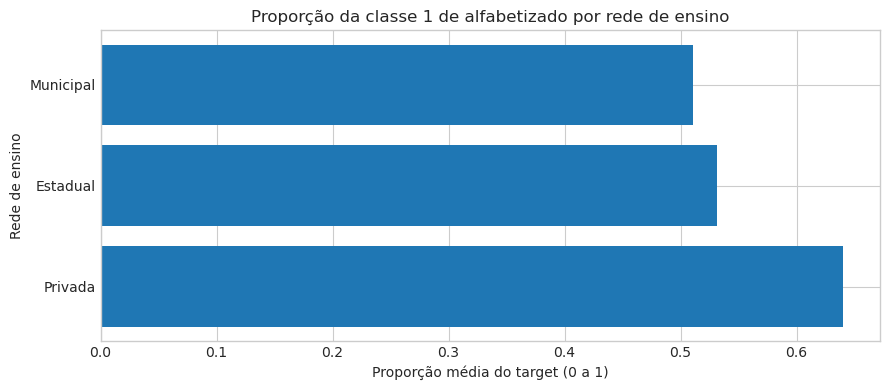

In [8]:
# Agregar os indicadores por código da rede, sem exibir a tabela ainda
resumo_rede = (
    lf.group_by(COL_REDE)
      .agg(construir_agregacao([COL_REDE]))
      .sort("quantidade_registros", descending=True)
      .collect()
      
)

# Obter a descrição correspondente a cada código
mapa_redes = (
    lf.select("rede", "rede_descricao")
      .unique()
      .collect()
      
)

# Associar os nomes das redes aos resultados
resumo_rede = resumo_rede.join(
    mapa_redes,
    on="rede",
    how="left"
)

# Exibir somente a tabela com os nomes das redes
colunas_exibicao = [
    "rede_descricao",
    "quantidade_registros",
    "proporcao_alfabetizado",
    "proficiencia_media",
    "proficiencia_mediana",
    "presenca_media",
    "preenchimento_caderno_medio",
]

display(resumo_rede.select([c for c in colunas_exibicao if c in resumo_rede.columns]))

# Gerar o gráfico com os nomes das redes
grafico = resumo_rede.drop_nulls("proporcao_alfabetizado").sort("proporcao_alfabetizado", descending=True)

plt.figure(figsize=(9, 4))
plt.barh(grafico["rede_descricao"].to_list(), grafico["proporcao_alfabetizado"].to_numpy())
plt.title("Proporção da classe 1 de alfabetizado por rede de ensino")
plt.xlabel("Proporção média do target (0 a 1)")
plt.ylabel("Rede de ensino")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "223_6_comparacao_por_rede_de_ensino_01.png"); plt.show()


## 7. Validação do recorte por série

A base consolidada utilizada neste projeto contém registros referentes exclusivamente à série 2, conforme verificado na coluna `serie`.

Como o objetivo do estudo é analisar o índice de alfabetização dos alunos da segunda série, não é necessário realizar uma comparação entre séries. A análise será direcionada às diferenças entre municípios, unidades federativas (UF) e redes de ensino, mantendo a série 2 como recorte fixo.

Essa validação garante que as análises seguintes estejam alinhadas ao escopo do projeto.


In [9]:
# Validar quais séries estão presentes na base
series_disponiveis = (
    lf.select(COL_SERIE)
      .drop_nulls()
      .unique()
      .sort(COL_SERIE)
      .collect()
)

display(series_disponiveis)

valores_serie = series_disponiveis[COL_SERIE].to_list()

if valores_serie == [2]:
    print("Validação concluída: todos os registros pertencem à série 2.")
else:
    print(
        "Atenção: foram encontrados valores diferentes de 2 "
        "ou mais de uma série na base:",
        valores_serie
    )


serie
i32
2


Validação concluída: todos os registros pertencem à série 2.


## 8. Diferenças entre municípios

A análise municipal usa um limite mínimo de registros para reduzir a instabilidade de grupos muito pequenos. O limite pode ser ajustado conforme o volume observado. A tabela completa de municípios fica disponível para inspeção, e as visualizações mostram apenas os municípios com amostra suficiente.


In [10]:
MIN_REGISTROS_MUNICIPIO = 30

if COL_MUNICIPIO is None:
    print("Análise municipal não executada: não foi encontrada uma coluna identificadora de município.")
else:
    grupos_municipio = [c for c in [COL_UF, COL_MUNICIPIO] if c is not None]
    resumo_municipio = (
        lf.group_by(grupos_municipio)
          .agg(construir_agregacao(grupos_municipio))
          .sort("quantidade_registros", descending=True)
          .collect()
    )
    print("Municípios/grupos encontrados:", resumo_municipio.height)
    display(resumo_municipio.head(30))
    municipios_validos = resumo_municipio.filter(pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
    print(f"Grupos com pelo menos {MIN_REGISTROS_MUNICIPIO} registros:", municipios_validos.height)
    if COL_TARGET and "proporcao_alfabetizado" in municipios_validos.columns and not municipios_validos.is_empty():
        print("Menores proporções de alfabetizado entre grupos com amostra mínima:")
        display(municipios_validos.sort("proporcao_alfabetizado").head(15))
        print("Maiores proporções de alfabetizado entre grupos com amostra mínima:")
        display(municipios_validos.sort("proporcao_alfabetizado", descending=True).head(15))


Municípios/grupos encontrados: 5548


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64,f64
"""SP""","""São Paulo""",107729,0.495763,748.632258,751.676226,0.876134,0.876022
"""RJ""","""Rio de Janeiro""",104495,0.514206,744.968275,752.2804,0.84472,0.84472
"""AM""","""Manaus""",63620,0.396416,737.510802,745.98,0.740616,0.740616
"""MG""","""Belo Horizonte""",39996,0.558031,754.208657,759.88,0.85151,0.85151
"""CE""","""Fortaleza""",38262,0.714233,774.20998,784.31,0.958105,0.958105
…,…,…,…,…,…,…,…
"""PB""","""João Pessoa""",13059,0.436481,743.785276,746.041528,0.838962,0.838962
"""GO""","""Aparecida de Goiânia""",12953,0.561106,750.915971,757.855774,0.86451,0.864124
"""PR""","""Londrina""",11539,0.628911,758.862415,763.26,0.84834,0.84834


Grupos com pelo menos 30 registros: 5445
Menores proporções de alfabetizado entre grupos com amostra mínima:


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64,f64
"""GO""","""Santa Helena de Goiás""",410,0.0,null,null,0.0,0.0
"""BA""","""Macururé""",89,0.078652,684.199698,682.84,0.932584,0.932584
"""RN""","""Paraú""",43,0.093023,707.696348,713.5288,0.674419,0.674419
"""TO""","""Filadélfia""",156,0.108974,693.483857,690.64,0.884615,0.884615
"""AC""","""Santa Rosa do Purus""",76,0.118421,702.652759,716.46,0.763158,0.763158
…,…,…,…,…,…,…,…
"""TO""","""Barra do Ouro""",163,0.128834,705.570697,705.047406,0.907975,0.907975
"""AM""","""Careiro""",1035,0.133333,720.480554,732.68,0.355556,0.355556
"""BA""","""Itaju do Colônia""",171,0.140351,707.738599,708.791418,0.807018,0.807018


Maiores proporções de alfabetizado entre grupos com amostra mínima:


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64,f64
"""CE""","""Coreaú""",510,1.0,868.104181,871.837387,1.0,1.0
"""PI""","""Caldeirão Grande do Piauí""",60,1.0,826.485582,838.136397,1.0,1.0
"""PI""","""Vila Nova do Piauí""",45,1.0,810.509448,810.57,1.0,1.0
"""CE""","""Nova Olinda""",430,0.997674,853.682992,857.073662,1.0,1.0
"""CE""","""Piquet Carneiro""",331,0.996979,831.791212,830.99,0.996979,0.996979
…,…,…,…,…,…,…,…
"""CE""","""Forquilha""",470,0.987234,861.760029,869.500064,0.987234,0.987234
"""CE""","""Novo Oriente""",759,0.985507,826.070941,829.38,0.992095,0.992095
"""CE""","""Cariré""",394,0.984772,839.841254,839.86305,0.992386,0.992386


In [11]:
display(
    resumo_municipio.filter(
        (pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
        & pl.col("proficiencia_media").is_not_null()
    ).sort("proporcao_alfabetizado").select(["sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado", "proficiencia_media"]).head(10)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media
str,str,u32,f64,f64
"""BA""","""Macururé""",89,0.078652,684.199698
"""RN""","""Paraú""",43,0.093023,707.696348
"""TO""","""Filadélfia""",156,0.108974,693.483857
"""AC""","""Santa Rosa do Purus""",76,0.118421,702.652759
"""RN""","""Poço Branco""",207,0.120773,701.941334
"""BA""","""Arataca""",172,0.122093,707.40482
"""MG""","""São João das Missões""",449,0.122494,727.812758
"""SE""","""Pedrinhas""",119,0.12605,694.201638
"""BA""","""Buritirama""",317,0.126183,701.39563


In [12]:
(
    lf.filter(
        (pl.col("sigla_uf") == "GO") &
        (pl.col("nome_municipio") == "Santa Helena de Goiás")
    )
    .group_by("alfabetizado")
    .agg([
        pl.len().alias("quantidade_registros"),
        pl.col("proficiencia").is_null().sum().alias("proficiencia_nula"),
        pl.col("presenca").mean().alias("presenca_media"),
        pl.col("preenchimento_caderno").mean().alias("preenchimento_caderno_medio"),
    ])
    .sort("alfabetizado")
    .collect()
)


alfabetizado,quantidade_registros,proficiencia_nula,presenca_media,preenchimento_caderno_medio
i32,u32,u32,f64,f64
0,410,410,0.0,0.0


In [13]:
municipios_sem_proficiencia = resumo_municipio.filter(pl.col("proficiencia_media").is_null())
print("Quantidade de grupos municipais sem proficiência média:", municipios_sem_proficiencia.height)
display(municipios_sem_proficiencia.select([
    "sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado",
    "proficiencia_media", "presenca_media", "preenchimento_caderno_medio",
]).head(20))


Quantidade de grupos municipais sem proficiência média: 1


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64
"""GO""","""Santa Helena de Goiás""",410,0.0,null,0.0,0.0


In [14]:
display(
    resumo_municipio.filter(
        (pl.col("proporcao_alfabetizado") == 0) & pl.col("proficiencia_media").is_not_null()
    ).select([
        "sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado",
        "proficiencia_media", "presenca_media", "preenchimento_caderno_medio",
    ]).head(20)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media,presenca_media,preenchimento_caderno_medio
str,str,u32,f64,f64,f64,f64


In [15]:
display(
    resumo_municipio.filter(pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
    .sort("proporcao_alfabetizado").select(["sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado", "proficiencia_media"]).head(10)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media
str,str,u32,f64,f64
"""GO""","""Santa Helena de Goiás""",410,0.0,null
"""BA""","""Macururé""",89,0.078652,684.199698
"""RN""","""Paraú""",43,0.093023,707.696348
"""TO""","""Filadélfia""",156,0.108974,693.483857
"""AC""","""Santa Rosa do Purus""",76,0.118421,702.652759
"""RN""","""Poço Branco""",207,0.120773,701.941334
"""BA""","""Arataca""",172,0.122093,707.40482
"""MG""","""São João das Missões""",449,0.122494,727.812758
"""SE""","""Pedrinhas""",119,0.12605,694.201638


In [16]:
display(
    resumo_municipio.filter(
        (pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
        & pl.col("proficiencia_media").is_not_null()
    ).sort("proporcao_alfabetizado", descending=True).select(["sigla_uf", "nome_municipio", "quantidade_registros", "proporcao_alfabetizado", "proficiencia_media"]).head(10)
)


sigla_uf,nome_municipio,quantidade_registros,proporcao_alfabetizado,proficiencia_media
str,str,u32,f64,f64
"""CE""","""Coreaú""",510,1.0,868.104181
"""PI""","""Caldeirão Grande do Piauí""",60,1.0,826.485582
"""PI""","""Vila Nova do Piauí""",45,1.0,810.509448
"""CE""","""Nova Olinda""",430,0.997674,853.682992
"""CE""","""Piquet Carneiro""",331,0.996979,831.791212
"""CE""","""Pedra Branca""",694,0.991354,836.78676
"""CE""","""Milhã""",303,0.990099,819.078001
"""CE""","""Pacujá""",163,0.98773,831.661991
"""CE""","""Itatira""",483,0.987578,832.117302


In [17]:
print(lf.select("alfabetizado").unique().sort("alfabetizado").collect())


shape: (2, 1)
┌──────────────┐
│ alfabetizado │
│ ---          │
│ i32          │
╞══════════════╡
│ 0            │
│ 1            │
└──────────────┘


In [18]:
municipios_validos = resumo_municipio.filter(
    (pl.col("quantidade_registros") >= MIN_REGISTROS_MUNICIPIO)
    & pl.col("proficiencia_media").is_not_null()
)
print("Grupos municipais válidos para comparação:", municipios_validos.height)
print("Menor proporção observada:", round(municipios_validos["proporcao_alfabetizado"].min() * 100, 2), "%")
print("Maior proporção observada:", round(municipios_validos["proporcao_alfabetizado"].max() * 100, 2), "%")
print("Mediana das proporções municipais:", round(municipios_validos["proporcao_alfabetizado"].median() * 100, 2), "%")


Grupos municipais válidos para comparação: 5444
Menor proporção observada: 7.87 %
Maior proporção observada: 100.0 %
Mediana das proporções municipais: 56.55 %


## 9. Recorte combinado: UF, rede e série

O recorte combinado ajuda a observar se as diferenças encontradas em análises isoladas persistem quando cruzamos as dimensões. Para evitar combinações excessivamente detalhadas, exibimos os grupos com maior volume de registros.


In [19]:
grupos_combinados = [c for c in [COL_UF, COL_REDE, COL_SERIE] if c is not None]

if len(grupos_combinados) < 2:
    print("Recorte combinado não executado: são necessárias pelo menos duas dimensões disponíveis.")
else:
    resumo_combinado = (
        lf.group_by(grupos_combinados)
          .agg(construir_agregacao(grupos_combinados))
          .sort("quantidade_registros", descending=True)
          .collect()
          
    )
    print("Quantidade de combinações observadas:", len(resumo_combinado))
    display(resumo_combinado.head(50))


Quantidade de combinações observadas: 51


sigla_uf,rede,serie,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
str,i32,i32,u32,f64,f64,f64,f64,f64
"""SP""",3,2,337804,0.496356,747.320418,750.942142,0.884939,0.884844
"""MG""",3,2,325723,0.583444,754.68619,760.48,0.887782,0.887782
"""RJ""",3,2,310978,0.448527,738.940132,746.665751,0.821508,0.821508
"""PR""",3,2,277041,0.622673,756.413252,761.335787,0.862194,0.862194
"""BA""",3,2,252748,0.319397,725.523223,729.62,0.870523,0.870523
…,…,…,…,…,…,…,…,…
"""PE""",2,2,330,0.693939,762.671922,770.780885,0.915152,0.915152
"""MA""",2,2,307,0.687296,768.885844,774.060079,0.918567,0.918567
"""PI""",2,2,289,0.564014,754.232457,757.03,0.903114,0.903114


## 10. Recorte por ano de referência, quando disponível

O ano é apresentado como dimensão categórica. Este recorte é uma comparação descritiva por período; a investigação temporal aprofundada será tratada no TC3-48. Mudanças na quantidade de registros entre anos não significam, por si só, erros ou duplicidades: podem refletir coortes, ingresso, saída ou mudanças de cobertura.


In [20]:
resumo_ano = analisar_grupo(COL_ANO, "ano de referência")


Quantidade de categorias em ano de referência: 2


ano_referencia,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio
i64,u32,f64,f64,f64,f64,f64
2024,2120560,0.522088,749.042072,753.95,0.873726,0.873284
2023,1747439,0.502122,747.563828,752.147831,0.860149,0.860007


## 11. Síntese automática dos resultados

A síntese abaixo registra os principais grupos observados e as limitações que devem acompanhar a interpretação. Os resultados devem ser revisados após a execução completa do notebook.


In [21]:
achados = [
    {
        "tema": "Distribuição geral do target",
        "observacao": (
            "A base apresenta aproximadamente 51,31% dos registros "
            "na classe 1 e 48,69% na classe 0."
        ),
        "limitacao": (
            "A variável alfabetizado foi utilizada conforme recebida "
            "na base, sem recalcular a classificação."
        )
    },
    {
        "tema": "Diferenças entre redes de ensino",
        "observacao": (
            "A proporção da classe 1 foi de 51,07% na rede municipal, "
            "53,15% na estadual e 64,00% na privada."
        ),
        "limitacao": (
            "A rede privada possui apenas 25 registros, quantidade "
            "insuficiente para uma comparação robusta."
        )
    },
    {
        "tema": "Diferenças entre municípios",
        "observacao": (
            "Foram identificados 5.444 grupos municipais com pelo menos "
            "30 registros e proficiência média disponível. As proporções "
            "variaram de 7,87% a 100%, com mediana de 56,55%."
        ),
        "limitacao": (
            "As proporções são descritivas e dependem da composição e "
            "da cobertura dos registros de cada município."
        )
    },
    {
        "tema": "Registros sem proficiência",
        "observacao": (
            "Santa Helena de Goiás apresentou 410 registros com "
            "alfabetizado igual a 0, proficiência ausente, presença "
            "igual a 0 e preenchimento do caderno igual a 0."
        ),
        "limitacao": (
            "Não é possível concluir que esses registros representem "
            "alunos não alfabetizados sem investigar a origem dos dados."
        )
    },
    {
        "tema": "Relação com o TC3-46",
        "observacao": (
            "O TC3-46 identificou correlação de aproximadamente 0,796 "
            "entre proficiencia e alfabetizado."
        ),
        "limitacao": (
            "A correlação não comprova causalidade nem data leakage. "
            "A origem e a disponibilidade temporal das variáveis "
            "devem ser verificadas antes da modelagem."
        )
    }
]

display(pl.DataFrame(achados))


tema,observacao,limitacao
str,str,str
"""Distribuição geral do target""","""A base apresenta aproximadamen…","""A variável alfabetizado foi ut…"
"""Diferenças entre redes de ensi…","""A proporção da classe 1 foi de…","""A rede privada possui apenas 2…"
"""Diferenças entre municípios""","""Foram identificados 5.444 grup…","""As proporções são descritivas …"
"""Registros sem proficiência""","""Santa Helena de Goiás apresent…","""Não é possível concluir que es…"
"""Relação com o TC3-46""","""O TC3-46 identificou correlaçã…","""A correlação não comprova caus…"


## 12. Conclusão

A análise exploratória do TC3-47 permitiu investigar diferenças na proporção de registros classificados como alfabetizados entre unidades federativas, redes de ensino e municípios, considerando a base disponível e o recorte da segunda série.

Na comparação entre redes de ensino, a proporção da classe 1 foi de 51,07% na rede municipal, 53,15% na estadual e 64,00% na privada. Entretanto, a rede privada possui apenas 25 registros, o que limita a confiabilidade dessa comparação.

Na análise municipal, foram identificados 5.444 grupos com pelo menos 30 registros e proficiência média disponível. As proporções observadas variaram de 7,87% a 100%, com mediana de 56,55%. Essa amplitude evidencia diferenças descritivas entre os grupos analisados, mas não permite atribuir suas causas ao município ou a outras características sem investigações adicionais.

Também foi identificado um grupo municipal com 410 registros sem proficiência disponível, presença igual a zero e preenchimento do caderno igual a zero. Esse caso requer investigação da origem dos dados antes de qualquer interpretação sobre alfabetização.

Os resultados devem ser interpretados considerando a cobertura dos dados, a quantidade de registros válidos por grupo e as limitações dos indicadores utilizados. A variável `alfabetizado` foi utilizada conforme recebida na base, sem recalcular sua classificação. Além disso, a relação entre `proficiencia` e `alfabetizado`, observada no TC3-46, deve ser investigada antes da modelagem para avaliar a disponibilidade temporal das informações e o possível risco de *data leakage*.

Conclui-se que o TC3-47 contribui para o entendimento das diferenças observadas na base e fornece subsídios para as próximas etapas do projeto. As comparações realizadas são descritivas e não devem ser interpretadas como comprovação de causalidade nem como reprodução automática do índice oficial de alfabetização.
